In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.datasets import mnist

from sklearn.model_selection import train_test_split

In [30]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))

In [31]:
numA = []
numB = []

for i in range(len(X_train)):
    if(y_train[i] == 6):
        numA.append(X_train[i])
    elif(y_train[i] == 8):
        numB.append(X_train[i])
    else: 
        continue

numA = np.array(numA, dtype="float32")
numB = np.array(numB, dtype="float32")

In [32]:
numA, numA_test = train_test_split(numA, train_size=0.8, random_state=42)
numB, numB_test = train_test_split(numB, train_size=0.8, random_state=42)

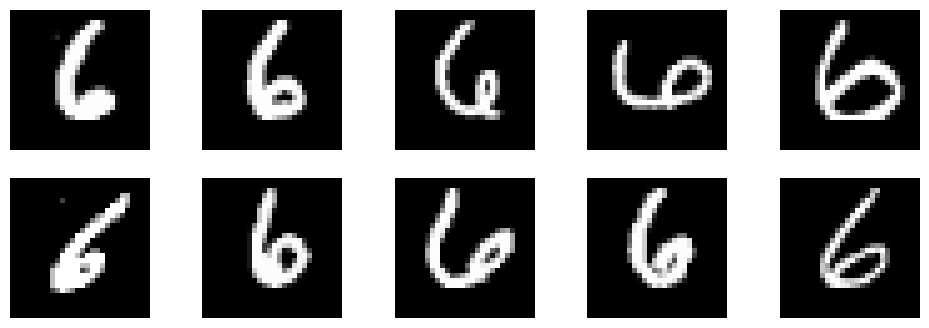

In [33]:
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2, 5,i+1)
    plt.imshow(numA[i].reshape(28,28), cmap="grey")
    plt.axis("off")

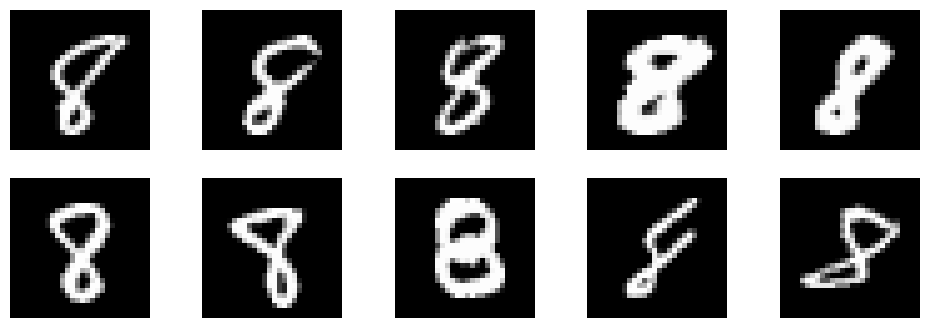

In [34]:
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2, 5,i+1)
    plt.imshow(numB[i].reshape(28,28), cmap="grey")
    plt.axis("off")

In [35]:
encoder = Sequential([
    Input(shape=(784, )),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(20, activation="relu", name="latent_rep")
])

encoder.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_rep (Dense)              │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 568,724 (2.17 MB)

 Trainable params: 568,724 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
decoderA = Sequential([
    Input(shape=(20, )),
    Dense(128, activation="relu"),
    Dense(256, activation="relu"),
    Dense(512, activation="relu"),
    Dense(784, activation="sigmoid"),
])

decoderB = Sequential([
    Input(shape=(20, )),
    Dense(128, activation="relu"),
    Dense(256, activation="relu"),
    Dense(512, activation="relu"),
    Dense(784, activation="sigmoid"),
])

decoderA.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                │ (None, 128)            │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,488 (2.17 MB)

 Trainable params: 569,488 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
autoencoderA = Sequential([encoder, decoderA])
autoencoderB = Sequential([encoder, decoderB])

autoencoderA.compile(optimizer="adam", loss="binary_crossentropy")
autoencoderB.compile(optimizer="adam", loss="binary_crossentropy")

In [38]:
autoencoderA.fit(numA, numA, epochs=10, batch_size=32)

Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2265
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1572
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1354
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1228
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1159
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1094
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1050
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1024
Epoch 9/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1005
Epoch 10/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0987


In [39]:
autoencoderB.fit(numB, numB, epochs=10, batch_size=32)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2141
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1514
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1391
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1321
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1274
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1240
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1217
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1196
Epoch 9/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1179
Epoch 10/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1164


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


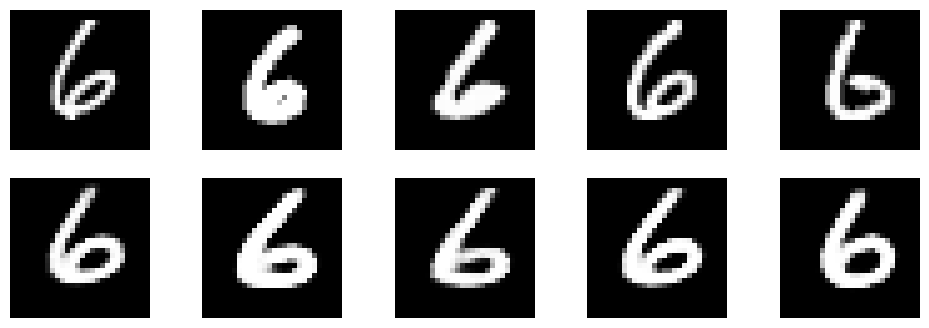

In [45]:
#a->a

reconA = autoencoderA.predict(numA_test[:5])

plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(numA_test[i].reshape(28,28), cmap="grey")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(reconA[i].reshape(28, 28), cmap="grey")
    plt.axis("off")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


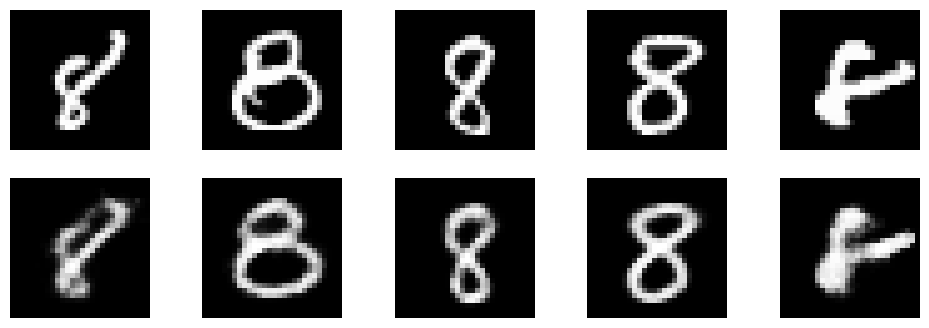

In [46]:
#b->b

reconB = autoencoderB.predict(numB_test[:5])

plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(numB_test[i].reshape(28,28), cmap="grey")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(reconB[i].reshape(28, 28), cmap="grey")
    plt.axis("off")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


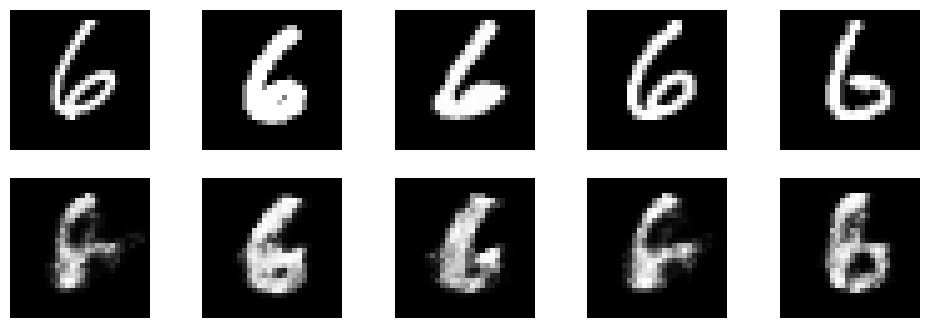

In [48]:
#a->b

latentA = encoder.predict(numA_test[:10])
reconAB = decoderB.predict(latentA)

plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(numA_test[i].reshape(28,28), cmap="grey")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(reconAB[i].reshape(28, 28), cmap="grey")
    plt.axis("off")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


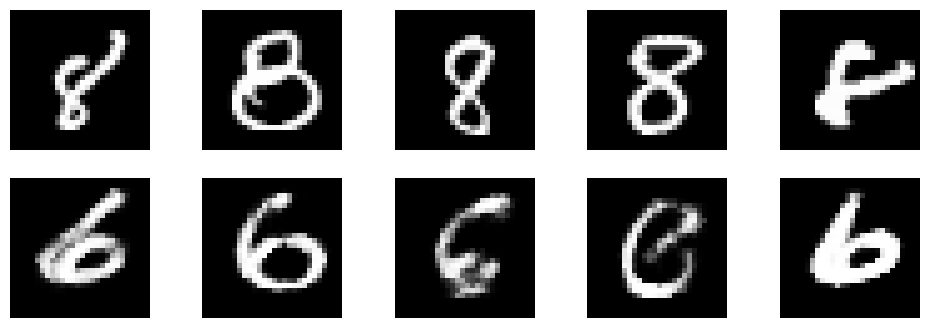

In [49]:
#b->a

latentB = encoder.predict(numB_test[:10])
reconBA = decoderA.predict(latentB)

plt.figure(figsize=(12,4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(numB_test[i].reshape(28,28), cmap="grey")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(reconBA[i].reshape(28, 28), cmap="grey")
    plt.axis("off")